# Controlled processes

**When a forecaster fails on a messy series, you want to know which part of the mess broke it, and for that you need series whose recipe you control, one ingredient at a time.**

This chapter builds four recipe families: a composed series (a straight line, a repeating cycle and one kind of noise, with optional jumps and a change of rules at a step you choose), Merton jumps (a price that drifts and sometimes jumps), GARCH (calm and stormy periods) and hidden Markov regimes (a market that switches between states nobody can see). For each recipe it also builds the answer key from the history alone, with exact formulas where they exist and simulation where they don't, and it records which.

You will see ingredients added one at a time with the same random draws, why prices, log prices and returns need different answer keys, an answer key that widens after a storm, and one that infers a hidden regime without peeking.

**Development notebook.** Library cells are collapsed; expand them to edit the code, then follow the [build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp processes

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import kurtosis
from timegym import Scenario

%matplotlib inline
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})
pd.set_option('display.max_colwidth', None)
BLUE = '#0000CC'


def draw_case(ax, case, title, last=48):
    # The end of the history, what actually happened, and the answer key with its 80% range.
    history = case.task.context.iloc[-last:, 0]
    low, high = case.reference.quantile((.1, .9))[:, 0].T
    ax.scatter(history.index, history, s=6, color='0.65', zorder=3, label='History')
    ax.scatter(case.observed.index, case.observed.iloc[:, 0], s=8, color='0.3', zorder=3,
               label='What actually happened')
    ax.fill_between(case.reference.index, low, high, color='0.88', linewidth=0, zorder=1,
                    label='Answer key, 80% range')
    ax.plot(case.reference.index, case.reference.mean[:, 0], color='0.2', linewidth=0.9, zorder=2,
            label='Answer key (mean)')
    ax.axvline(case.task.future_index[0] - 0.5, color=BLUE, linestyle='--', linewidth=0.8)
    ax.set_title(title, fontsize=10)

## What the model sees, and what the answer key knows

The model gets the history and the dates to forecast, nothing else. The recipe's settings, any future change of rules, hidden regimes and future shocks stay with the evaluator. The answer key knows the settings but, like the model, conditions only on the history: it rebuilds GARCH volatility from the observed returns and works out regime probabilities from them, rather than copying the simulated hidden path.

The four families and their default settings are registered in `_PROCESS_REGISTRY` below. Everything the one-series and several-series builders share (setting checks, random streams, unit conversions and case assembly) lives in `_process_common`, so [chapter 15](15_joint_processes.ipynb) can reuse it without depending on this chapter's builders.

In [3]:
#| export _process_common
from __future__ import annotations
from copy import deepcopy
import numpy as np
import pandas as pd
from timegym._internal import positive_int, nonnegative_int, _real_array
from timegym.contracts import Case, ForecastTask, Reference, SimulationReference, MANIFEST_SCHEMA_VERSION

_CHANGE_FIELDS = {'intercept', 'slope', 'amplitude', 'period', 'phase', 'sigma'}
_TAIL_TOLERANCE = 1e-12

_PROCESS_REGISTRY = {
    'composite': dict(defaults=dict(intercept=0., slope=0., amplitude=0., period=12., phase=0.,
                      sigma=1., residual='white_noise', jump_rate=0., jump_mean=0.,
                      jump_sigma=0., change_point=None, changes={}), scalar='_composite', joint='_joint_composite', label='Composite'),
    'merton_jump_diffusion': dict(defaults=dict(mu=.05, sigma=.2, jump_rate=.5, jump_mean=-.1,
                                 jump_sigma=.15, dt=1/252, initial_price=100., output='price'), scalar='_merton', joint='_joint_merton', label='Merton jump diffusion'),
    'garch': dict(defaults=dict(mu=0., omega=.00001, alpha=.08, beta=.9,
                  initial_variance=None, initial_price=100., output='log_return'), scalar='_garch', joint='_joint_garch', label='GARCH(1,1)'),
    'markov_switching': dict(defaults=dict(transition=[[.97, .03], [.08, .92]], initial_probs=[.8, .2],
                            regime_mu=[.08, -.15], regime_sigma=[.15, .45],
                            regime_jump_rate=[0., 0.], regime_jump_mean=[0., 0.],
                            regime_jump_sigma=[0., 0.], dt=1/252,
                            initial_price=100., output='log_return'), scalar='_markov', joint='_joint_markov', label='Hidden Markov regimes'),
}
_DEFAULTS = {kind: entry['defaults'] for kind, entry in _PROCESS_REGISTRY.items()}
PROCESS_KINDS = tuple(_PROCESS_REGISTRY)


In [4]:
#| export processes
from __future__ import annotations
from copy import deepcopy
import numpy as np
from scipy.special import logsumexp
from scipy.stats import poisson
from timegym import joint_processes
from timegym._process_common import (
    PROCESS_KINDS, resolve_process, _DEFAULTS, _PROCESS_REGISTRY,
    _CHANGE_FIELDS, _TAIL_TOLERANCE, _finite, _exp, _log_cumulant, _streams, _rng,
    _to_values, _observed_returns, _transform_samples, _build_case,
    _regime_arrays, _common_deterministic_return,
)

__all__ = ['PROCESS_KINDS', 'resolve_process', 'process_label', 'generate_process']


In [5]:
#| export _process_common
def _scalar(name, value, *, minimum=None, positive=False):
    a = _real_array(value, name)
    if a.ndim != 0 or not np.isfinite(a):
        raise ValueError(f'{name} must be a finite real scalar')
    result = float(a)
    if positive and result <= 0 or minimum is not None and result < minimum:
        raise ValueError(f'{name} must be {"positive" if positive else f">= {minimum}"}')
    return result

In [6]:
#| export _process_common
def _finite(value, purpose):
    a = np.asarray(value, dtype=float)
    if not np.isfinite(a).all():
        raise ValueError(f'{purpose} overflowed; reduce horizon, rates, scales or time step')
    return a

In [7]:
#| export _process_common
def _exp(value, purpose):
    with np.errstate(over='ignore', under='ignore', invalid='ignore'):
        result = np.exp(value)
    _finite(result, purpose)
    if np.any(result == 0):
        raise ValueError(f'{purpose} underflowed; reduce horizon, rates, scales or time step')
    return result

In [8]:
#| export _process_common
def _log_cumulant(k, mu, sigma, rate, jump_mean, jump_sigma, dt):
    """Physical-measure Merton convention: E[S(t+dt)/S(t)] = exp(mu*dt)."""
    with np.errstate(over='ignore', invalid='ignore'):
        kappa = np.expm1(jump_mean + .5 * jump_sigma**2)
        value = (k * (mu - .5*sigma**2 - rate*kappa) + .5*k*k*sigma**2
                 + rate*np.expm1(k*jump_mean + .5*k*k*jump_sigma**2)) * dt
    return _finite(value, 'Log-return cumulant')

## Settings are checked before anything is generated

`resolve_process` fills in the defaults and rejects, with a message, any setting it doesn't know, any output unit a family doesn't support, probabilities that don't add up and GARCH volatility that would grow forever. It also expands every setting to one value per series, with helpers that chapter 15's joint recipes share.

In [9]:
#| export _process_common
def _vector(value, name, d, *, minimum=None, positive=False):
    a = _real_array(value, name)
    if a.ndim == 0:
        a = np.full(d, float(a))
    if a.shape != (d,) or not np.isfinite(a).all():
        raise ValueError(f'{name} must be a finite scalar or vector of length n_targets')
    if positive and np.any(a <= 0) or minimum is not None and np.any(a < minimum):
        raise ValueError(f'{name} must be {"positive" if positive else f">= {minimum}"}')
    return a

In [10]:
#| export _process_common
def _correlation(value, d, name='correlation', *, definite=False):
    a = _real_array(value, name)
    if a.ndim == 0:
        rho = float(a)
        if not np.isfinite(rho) or not (-1/(d-1) if d > 1 else -1) <= rho <= 1:
            raise ValueError(f'{name}: invalid equicorrelation for {d} targets')
        a = np.full((d, d), rho)
        np.fill_diagonal(a, 1.)
    if (a.shape != (d, d) or not np.isfinite(a).all()
            or not np.allclose(a, a.T, atol=1e-12, rtol=0)
            or not np.allclose(np.diag(a), 1., atol=1e-12, rtol=0)):
        raise ValueError(f'{name} must be a symmetric correlation matrix of shape ({d}, {d})')
    a = (a+a.T)/2
    np.fill_diagonal(a, 1.)
    eigenvalues = np.linalg.eigvalsh(a)
    if eigenvalues.min() < -1e-12 or definite and eigenvalues.min() <= 1e-12:
        raise ValueError(f'{name} must be positive {"definite for multivariate regime filtering" if definite else "semidefinite"}')
    # Keep validated entries stable across manifest replay; factorization
    # clips only numerical eigenvalue roundoff in the separate sampler.
    return (a+a.T)/2

In [11]:
#| export _process_common
def _regime_vector(value, name, k, d, *, nonnegative=False, positive=False):
    a = _real_array(value, name)
    if a.shape == (k,):
        a = np.repeat(a[:, None], d, axis=1)
    if a.shape != (k, d) or not np.isfinite(a).all():
        raise ValueError(f'{name} must have shape (regimes,) or (regimes, n_targets)')
    if nonnegative and np.any(a < 0) or positive and np.any(a <= 0):
        raise ValueError(f'{name} must be {"positive" if positive else "nonnegative"}')
    return a

In [12]:
#| export _process_common
def _factor(matrix):
    values, vectors = np.linalg.eigh(matrix)
    return vectors*np.sqrt(np.maximum(values, 0.))

In [13]:
#| export _process_common
def _emission_law(p):
    """Joint Merton cumulants and multiplier covariance under one jump clock."""
    mu, sigma, jm, js = [np.asarray(p[key]) for key in ('mu', 'sigma', 'jump_mean', 'jump_sigma')]
    rate, dt = p['jump_rate'], p['dt']
    diffusion = np.outer(sigma, sigma)*p['correlation']
    jump = np.outer(js, js)*p['jump_correlation']
    kappa = np.expm1(jm+.5*js**2)
    drift = (mu-.5*sigma**2-rate*kappa)*dt
    mean = drift+rate*dt*jm
    covariance = dt*(diffusion+rate*(jump+np.outer(jm, jm)))
    growth = _exp(mu*dt, 'Expected price multiplier')
    jump_growth = _exp(jm+.5*js**2, 'Expected jump multiplier')
    cross_jump = np.outer(jump_growth, jump_growth)*np.expm1(jump)+np.outer(kappa, kappa)
    spread = dt*(diffusion+rate*cross_jump)
    growth_cov = np.outer(growth, growth)*np.expm1(spread)
    _finite([drift, mean], 'Return moments'); _finite(covariance, 'Return covariance')
    _finite(growth_cov, 'Price multiplier covariance')
    return dict(drift=drift, mean=mean, covariance=covariance, growth=growth,
                growth_covariance=growth_cov, spread=spread,
                diffusion_factor=_factor(diffusion*dt), jump_factor=_factor(jump),
                jump_mean=jm, intensity=rate*dt)

In [14]:
#| export _process_common
def _state_parameters(p, state):
    result = {name: p['regime_'+name][state] for name in ('mu', 'sigma', 'jump_rate', 'jump_mean', 'jump_sigma')}
    return dict(result, dt=p['dt'], correlation=p['regime_correlation'][state], jump_correlation=p['jump_correlation'])

In [15]:
#| export _process_common
def resolve_process(kind, parameters, context_length, horizon, n_targets, seed):
    """Resolve explicit dependence laws; scalar target parameters broadcast.

    Jump arrivals share one Poisson clock. Markov targets share one hidden
    chain, filtered from the complete observed vector. GARCH has target-wise
    recursions and constant conditional innovation correlation (CCC-GARCH).
    """
    if kind not in PROCESS_KINDS:
        raise ValueError(f"Unknown controlled process {kind!r}")
    positive_int(context_length, 'context_length'); positive_int(horizon, 'horizon')
    d = positive_int(n_targets, 'n_targets')
    nonnegative_int(seed, 'seed')
    if not isinstance(parameters, dict):
        raise TypeError('parameters must be a dictionary')
    extras = {'correlation'}
    if kind in ('composite', 'merton_jump_diffusion', 'markov_switching'):
        extras.add('jump_correlation')
    if kind == 'garch':
        extras |= {'moment_samples', 'moment_seed'}
    if kind == 'markov_switching':
        extras.add('regime_correlation')
    unknown = set(parameters)-set(_DEFAULTS[kind])-extras
    if unknown:
        raise ValueError(f'Unsupported parameters for {kind}: {sorted(unknown)}')
    p = deepcopy({**_PROCESS_REGISTRY[kind]['defaults'], **parameters})
    p['correlation'] = _correlation(p.get('correlation', 0.), d,
                                    definite=kind == 'markov_switching').tolist()
    if 'jump_correlation' in extras:
        p['jump_correlation'] = _correlation(p.get('jump_correlation', 0.), d, 'jump_correlation').tolist()
    if kind == 'composite':
        if p['residual'] not in ('white_noise', 'random_walk'):
            raise ValueError('residual must be white_noise or random_walk')
        for key in (*sorted(_CHANGE_FIELDS), 'jump_mean', 'jump_sigma'):
            p[key] = _vector(p[key], key, d, positive=key == 'period',
                              minimum=0 if key in ('sigma', 'jump_sigma') else None).tolist()
        p['jump_rate'] = _scalar('jump_rate', p['jump_rate'], minimum=0)
        if p['jump_rate'] > 1e6:
            raise ValueError('jump_rate must be <= 1e6 per step')
        if p['jump_rate'] and p['residual'] != 'random_walk':
            raise ValueError('Compound-Poisson jumps require residual=random_walk')
        if not isinstance(p['changes'], dict) or set(p['changes'])-_CHANGE_FIELDS:
            raise ValueError(f'changes may only contain {sorted(_CHANGE_FIELDS)}')
        p['changes'] = {key: _vector(v, key, d, positive=key == 'period',
                                      minimum=0 if key == 'sigma' else None).tolist()
                        for key, v in p['changes'].items()}
        if p['change_point'] is not None:
            p['change_point'] = nonnegative_int(p['change_point'], 'change_point')
            if not p['changes']:
                raise ValueError('change_point requires nonempty changes')
        elif p['changes']:
            raise ValueError('changes require change_point')
        return _scalar_parameters(p) if d == 1 else p
    p['initial_price'] = _vector(p['initial_price'], 'initial_price', d, positive=True).tolist()
    outputs = ('log_return', 'log_price') if kind == 'garch' else ('log_return', 'log_price', 'price')
    if p['output'] not in outputs:
        raise ValueError(f'{kind} output must be one of {outputs}')
    if kind == 'garch':
        for key in ('mu', 'omega', 'alpha', 'beta'):
            p[key] = _vector(p[key], key, d, positive=key == 'omega',
                              minimum=0 if key in ('alpha', 'beta') else None).tolist()
        persistence = np.array(p['alpha'])+p['beta']
        if np.any(persistence >= 1):
            raise ValueError('GARCH requires alpha + beta < 1 for every target')
        initial = np.array(p['omega'])/(1-persistence) if p['initial_variance'] is None else p['initial_variance']
        p['initial_variance'] = _vector(initial, 'initial_variance', d, positive=True).tolist()
        p['moment_samples'] = positive_int(p.get('moment_samples', 16384), 'moment_samples')
        if p['moment_samples'] < 2:
            raise ValueError('moment_samples must be an integer >= 2')
        p['moment_seed'] = nonnegative_int(p.get('moment_seed', 0), 'moment_seed')
        return _scalar_parameters(p) if d == 1 else p
    p['dt'] = _scalar('dt', p['dt'], positive=True)
    if kind == 'merton_jump_diffusion':
        for key in ('mu', 'sigma', 'jump_mean', 'jump_sigma'):
            p[key] = _vector(p[key], key, d, minimum=0 if key in ('sigma', 'jump_sigma') else None).tolist()
        p['jump_rate'] = _scalar('jump_rate', p['jump_rate'], minimum=0)
        if p['jump_rate']*p['dt'] > 1e6:
            raise ValueError('jump_rate * dt must be <= 1e6')
        for order in (1., 2.):
            _log_cumulant(order, *[np.asarray(p[key]) for key in
                ('mu', 'sigma', 'jump_rate', 'jump_mean', 'jump_sigma')], p['dt'])
        if d > 1:
            _emission_law(p)
        return _scalar_parameters(p) if d == 1 else p
    transition = _real_array(p['transition'], 'transition')
    if (transition.ndim != 2 or not len(transition) or transition.shape[0] != transition.shape[1]
            or not np.isfinite(transition).all() or np.any(transition < 0)
            or not np.allclose(transition.sum(1), 1., atol=1e-12, rtol=0)):
        raise ValueError('transition must be a square matrix of probabilities with row sums one')
    k = len(transition)
    p['transition'] = (transition/transition.sum(1, keepdims=True)).tolist()
    initial = _real_array(p['initial_probs'], 'initial_probs')
    if initial.shape != (k,) or not np.isfinite(initial).all() or np.any(initial < 0) or not np.isclose(initial.sum(), 1., atol=1e-12, rtol=0):
        raise ValueError('initial_probs must be regime probabilities summing to one')
    p['initial_probs'] = (initial/initial.sum()).tolist()
    for key in ('regime_mu', 'regime_sigma', 'regime_jump_mean', 'regime_jump_sigma'):
        p[key] = _regime_vector(p[key], key, k, d, positive=key == 'regime_sigma' and d > 1,
                                nonnegative=key in ('regime_sigma', 'regime_jump_sigma')).tolist()
    rate = _real_array(p['regime_jump_rate'], 'regime_jump_rate')
    if rate.shape != (k,) or not np.isfinite(rate).all() or np.any(rate < 0) or np.any(rate*p['dt'] > 100):
        raise ValueError('regime_jump_rate must have one nonnegative entry per regime and rate * dt <= 100')
    p['regime_jump_rate'] = rate.tolist()
    correlations = p.get('regime_correlation')
    if correlations is None:
        correlations = [p['correlation']]*k
    correlations = _real_array(correlations, 'regime_correlation')
    if correlations.shape != (k, d, d):
        raise ValueError('regime_correlation must have shape (regimes, n_targets, n_targets)')
    p['regime_correlation'] = [_correlation(c, d, 'regime_correlation', definite=True).tolist() for c in correlations]
    for state in range(k):
        state_parameters = _state_parameters(p, state)
        for order in (1., 2.):
            _log_cumulant(order, *[np.asarray(state_parameters[key]) for key in
                ('mu', 'sigma', 'jump_rate', 'jump_mean', 'jump_sigma')], p['dt'])
        if d > 1:
            _emission_law(state_parameters)
    if d == 1:
        scalar_parameters = _scalar_parameters(p)
        sigma = np.asarray(scalar_parameters['regime_sigma'])
        rate = np.asarray(scalar_parameters['regime_jump_rate'])
        jump_sigma = np.asarray(scalar_parameters['regime_jump_sigma'])
        has_atoms = np.any(sigma == 0)
        has_continuous = np.any((sigma > 0) | ((rate > 0) & (jump_sigma > 0)))
        if has_atoms and has_continuous:
            raise ValueError('Markov emissions must not mix point masses and continuous densities; use strictly positive regime_sigma in every regime, or entirely discrete emissions')
        if (has_atoms and p['output'] != 'log_return' and context_length > 1
                and not _common_deterministic_return(scalar_parameters)):
            raise ValueError('Discrete Markov emissions require output=log_return when conditioning on returns; reconstructing discrete returns from price/log_price loses exact support. A length-one level context or identical deterministic regimes is supported')
    return _scalar_parameters(p) if d == 1 else p

def _scalar_parameters(parameters):
    """Keep scalar manifests stable while sharing vector validation."""
    result = {}
    for key, value in parameters.items():
        if key in ('correlation', 'jump_correlation', 'regime_correlation', 'moment_samples', 'moment_seed'):
            continue
        if key == 'changes':
            value = {name: values[0] for name, values in value.items()}
        elif key in ('regime_mu', 'regime_sigma', 'regime_jump_mean', 'regime_jump_sigma'):
            value = [values[0] for values in value]
        elif key not in ('transition', 'initial_probs', 'regime_jump_rate') and isinstance(value, list):
            value = value[0]
        result[key] = value
    return result


In [16]:
#| export processes
def process_label(kind, parameters=None, *, target_index=None):
    """Human-readable mechanism and output units, retaining stable kind IDs."""
    if kind not in PROCESS_KINDS:
        return kind
    p = {**_DEFAULTS[kind], **({} if parameters is None else parameters)}
    if target_index is not None and kind == 'composite':
        p = deepcopy(p)
        for key in _CHANGE_FIELDS:
            value = np.asarray(p[key])
            if value.ndim == 1:
                p[key] = value[target_index]
            if key in p.get('changes', {}):
                value = np.asarray(p['changes'][key])
                if value.ndim == 1:
                    p['changes'][key] = value[target_index]
    if kind == 'composite':
        pieces = []
        if np.any(np.asarray(p['slope']) != 0) or np.any(np.asarray(p.get('changes', {}).get('slope', 0)) != 0):
            pieces.append('Linear trend')
        if np.any(np.asarray(p['amplitude']) != 0) or np.any(np.asarray(p.get('changes', {}).get('amplitude', 0)) != 0):
            pieces.append('Seasonality')
        pieces.append('white noise' if p['residual'] == 'white_noise' else 'accumulated shocks')
        if p['jump_rate']:
            pieces.append('jumps')
        label = ' + '.join(pieces)
        return label[0].upper() + label[1:] + (' (parameter change)' if p['change_point'] is not None else '')
    labels = {'merton_jump_diffusion': 'Geometric Brownian motion' if p.get('jump_rate', 0.) == 0 else _PROCESS_REGISTRY[kind]['label'],
              'garch': 'CCC-GARCH(1,1)' if np.asarray(p.get('mu', 0.)).size > 1 else _PROCESS_REGISTRY[kind]['label']}
    if kind == 'markov_switching':
        labels[kind] = 'Hidden regimes + jumps' if any(p['regime_jump_rate']) else _PROCESS_REGISTRY[kind]['label']
    units = {'price': 'price', 'log_price': 'log price', 'log_return': 'log returns'}
    return f'{labels[kind]} ({units[p["output"]]})'

### What did I just build?

`process_label` gives each recipe a plain name, with its output unit for the financial families; `Scenario.display_name` uses it. A mistyped or impossible setting fails as soon as the `Scenario` is created, with a message that says what to fix:

In [17]:
def spelled_out(settings):
    return ', '.join(f'{key}={value!r}' for key, value in settings.items())


examples = [
    ('composite', {'slope': .05, 'amplitude': 2.}),
    ('composite', {'amplitude': 2., 'residual': 'random_walk', 'change_point': 100, 'changes': {'amplitude': 4.}}),
    ('merton_jump_diffusion', {'jump_rate': 0.}),
    ('garch', {'output': 'log_price'}),
    ('markov_switching', {'regime_jump_rate': [3., 12.]}),
]
display(pd.DataFrame([{'kind': kind, 'settings': spelled_out(settings),
                       'name': Scenario(kind, parameters=settings).display_name}
                      for kind, settings in examples]))

mistakes = {
    'A typo': ('composite', {'amplitud': 2.}),
    'Jumps on fresh noise': ('composite', {'jump_rate': .1}),
    'Volatility that never settles': ('garch', {'alpha': .2, 'beta': .85}),
    'GARCH reported as prices': ('garch', {'output': 'price'}),
}
messages = {}
for mistake, (kind, settings) in mistakes.items():
    try:
        Scenario(kind, parameters=settings)
    except ValueError as error:
        messages[mistake] = str(error)
assert list(messages) == list(mistakes)  # every mistake fails when the Scenario is created
display(pd.DataFrame({'settings': [spelled_out(s) for _, s in mistakes.values()],
                      'message': list(messages.values())}, index=pd.Index(list(mistakes), name='mistake')))

,kind,settings,name
0,composite,"slope=0.05, amplitude=2.0",Linear trend + Seasonality + white noise
1,composite,"amplitude=2.0, residual='random_walk', change_point=100, changes={'amplitude': 4.0}",Seasonality + accumulated shocks (parameter change)
2,merton_jump_diffusion,jump_rate=0.0,Geometric Brownian motion (price)
3,garch,output='log_price',"GARCH(1,1) (log price)"
4,markov_switching,"regime_jump_rate=[3.0, 12.0]",Hidden regimes + jumps (log returns)


,settings,message
mistake,,
A typo,amplitud=2.0,Unsupported parameters for composite: ['amplitud']
Jumps on fresh noise,jump_rate=0.1,Compound-Poisson jumps require residual=random_walk
Volatility that never settles,"alpha=0.2, beta=0.85",GARCH requires alpha + beta < 1 for every target
GARCH reported as prices,output='price',"garch output must be one of ('log_return', 'log_price')"


A typo never falls back silently to a default, so you can't end up testing a different recipe from the one you meant. The second message is worth knowing: jumps move the level, which only accumulated shocks carry forward, so they need `residual='random_walk'`.

## Separate random streams, so one change keeps the rest of the luck

Each source of randomness has its own stream: the everyday shocks, how many jumps happen, how big they are, and the regime switches. Turn jumps on and, at the same seed, the everyday shocks stay exactly the same, so any change in a model's error comes from the jumps. The answer key draws its possible futures from separate streams again, so it never reuses the shocks behind what actually happened, even when the two seeds are the same number.

In [18]:
#| export _process_common
def _seed_sequence(seed, *, role=0, joint=False):
    """Roles: 0 observations, 1 reference draws, 2 covariance integration.

    The scalar and joint namespace tags preserve historical seeded paths.
    Scalar observations predate namespacing; evaluator streams are separate.
    """
    if joint:
        entropy = [0x4D564754, role, seed]
    elif role:
        entropy = [0x5447594D, seed] if role == 1 else [0x5447594D, role, seed]
    else:
        entropy = seed
    return np.random.SeedSequence(entropy)


def _streams(seed, *, role=0, joint=False):
    keys = ('diffusion', 'jump_counts', 'jump_sizes', 'states')
    sequence = _seed_sequence(seed, role=role, joint=joint)
    return dict(zip(keys, map(np.random.default_rng, sequence.spawn(len(keys)))))


def _rng(seed, *, role=0):
    return np.random.default_rng(_seed_sequence(seed, role=role))


In [19]:
#| export processes
def _jump_increment(rng, size, rate, mean, sigma):
    count = rng['jump_counts'].poisson(rate, size=size)
    return count*mean + np.sqrt(count)*sigma*rng['jump_sizes'].standard_normal(size)

In [20]:
#| export processes
def _merton_increment(rng, size, mu, sigma, rate, jump_mean, jump_sigma, dt):
    with np.errstate(over='ignore', invalid='ignore'):
        drift = (mu-.5*sigma**2-rate*np.expm1(jump_mean+.5*jump_sigma**2))*dt
    return _finite(drift + sigma*np.sqrt(dt)*rng['diffusion'].standard_normal(size)
                   + _jump_increment(rng, size, rate*dt, jump_mean, jump_sigma), 'Simulated log return')

In [21]:
#| export _process_common
def _assemble_case(kind, p, length, horizon, n_targets, seed, values, mean, covariance, conditioning, sampler, capabilities):
    names = ('y',) if n_targets == 1 else tuple(f'y{i}' for i in range(n_targets))
    index = pd.RangeIndex(length, length + horizon)
    values = _finite(values, 'Generated observations').reshape(length + horizon, n_targets)
    task = ForecastTask(pd.DataFrame(values[:length], columns=names), index)
    observed = pd.DataFrame(values[length:], index=index, columns=names)
    mean = _finite(mean, 'Conditional mean').reshape(horizon, n_targets)
    covariance = _finite(covariance, 'Conditional covariance')
    covariance = (covariance+covariance.T)/2
    # Only roundoff on a theoretically nonnegative diagonal is removable.
    diagonal = np.diag(covariance).copy()
    tolerance = 1e-10*max(1., float(np.max(np.abs(covariance))))
    if diagonal.min() < -tolerance:
        raise ValueError('Conditional variance lost numerical precision; rescale the process')
    np.fill_diagonal(covariance, np.maximum(diagonal, 0))
    conditioning = dict(observed_through=length-1, known_generator_parameters=True,
                        future_observations_used=False, **conditioning)
    reference_args = dict(mean=mean, variance=np.diag(covariance).reshape(horizon, n_targets).copy(),
                          covariance=covariance, index=task.future_index.copy(),
                          target_names=names, conditioning=conditioning)
    if sampler is None:
        reference = Reference(**reference_args)
    else:
        reference = SimulationReference(**reference_args, sampler=sampler,
                                        **capabilities)
    manifest = dict(schema_version=MANIFEST_SCHEMA_VERSION, kind=kind, context_length=length, horizon=horizon,
                    n_targets=n_targets, target_names=list(names), seed=int(seed), parameters=deepcopy(p),
                    reference_kind=reference.kind, conditioning=deepcopy(reference.conditioning), array_order='horizon_major_C')
    return Case(task, observed, reference, manifest)

def _build_case(builder, kind, parameters, context_length, horizon, n_targets, seed):
    with np.errstate(over='ignore', invalid='ignore'):
        result = builder(parameters, context_length, horizon, n_targets, seed)
    return _assemble_case(kind, parameters, context_length, horizon, n_targets, seed, *result)


## A composed series: a line, a cycle and one kind of noise

The fixed part is a straight line plus a repeating cycle, $m_t=b+ct+A\sin(2\pi t/P+\phi)$, set by `intercept`, `slope`, `amplitude`, `period` and `phase`. On top goes one kind of noise:

- **fresh noise** (`residual='white_noise'`, the default): $Y_t=m_t+\sigma_t Z_t$, a new shock each step that is gone by the next;
- **accumulated shocks** (`residual='random_walk'`): $Y_t=m_t+X_t$, where $X_t$ adds up every shock so far. Only these can also jump, by a random amount (`jump_mean`, `jump_sigma`), on average `jump_rate` times per step. The jumps add a fixed amount to the level, unlike the percentage jumps of the price recipes below.

A cycle repeats under fixed rules. A `change_point` changes the rules themselves (what is often called concept drift): from that step on, the settings listed in `changes` take their new values. The line is measured from step 0, so a new `intercept` or `slope` also moves the level at the change; that jump is deliberate, not smoothed away. The answer key knows the future schedule; the model only sees the history.

In [22]:
#| export processes
def _composite(p, length, horizon, n_targets, seed):
    t = np.arange(length+horizon, dtype=float)
    schedule = {}
    for key in _CHANGE_FIELDS:
        a = np.full(len(t), p[key], dtype=float)
        if p['change_point'] is not None and key in p['changes']:
            a[t >= p['change_point']] = p['changes'][key]
        schedule[key] = a
    with np.errstate(over='ignore', invalid='ignore'):
        signal = (schedule['intercept']+schedule['slope']*t + schedule['amplitude']
                  *np.sin(2*np.pi*t/schedule['period']+schedule['phase']))
    _finite(signal, 'Composite deterministic path')
    rng = _streams(seed)
    residual = np.empty(len(t))
    for i in range(len(t)):
        shock = schedule['sigma'][i]*rng['diffusion'].standard_normal()
        if p['residual'] == 'random_walk' and i == 0:
            residual[i] = 0.
        else:
            residual[i] = shock
            if p['residual'] == 'random_walk':
                residual[i] += residual[i-1] + _jump_increment(rng, None, p['jump_rate'], p['jump_mean'], p['jump_sigma'])
    values = signal+residual
    future_sigma = schedule['sigma'][length:]
    last_residual = float(values[length-1]-signal[length-1])
    if p['residual'] == 'white_noise':
        mean = signal[length:]
        covariance = np.diag(future_sigma**2)
    else:
        mean = signal[length:]+last_residual+np.arange(1, horizon+1)*p['jump_rate']*p['jump_mean']
        cumulative_variance = np.cumsum(future_sigma**2 + p['jump_rate']*(p['jump_sigma']**2+p['jump_mean']**2))
        covariance = cumulative_variance[np.minimum.outer(np.arange(horizon), np.arange(horizon))]
    conditioning = dict(residual=p['residual'], future_parameter_schedule_known=True,
                        schedule_convention='absolute_time_intercept_plus_slope_t',
                        residual_level_from_observed_history=last_residual if p['residual'] == 'random_walk' else None)
    sampler = None
    if p['jump_rate']:
        def sampler(n, sample_seed):
            rng = _streams(sample_seed, role=1)
            out = np.empty((n, horizon, 1))
            previous = np.full(n, last_residual)
            for h in range(horizon):
                previous = previous+future_sigma[h]*rng['diffusion'].standard_normal(n)+_jump_increment(rng, n, p['jump_rate'], p['jump_mean'], p['jump_sigma'])
                out[:, h, 0] = signal[length+h]+previous
            return out
    return values, mean, covariance, conditioning, sampler, {}

### Add one ingredient, keep the same luck

Four recipes, each adding one thing to the one before: a cycle with fresh noise; shocks that accumulate instead; jumps; and from step 100, a cycle twice as tall with noise of 0.8 instead of 0.3. All four use seed 11, so they share their random draws. When a model's error jumps between two rungs, the added ingredient is the cause, not the luck of the draw. [Composed and financial stresses](26_composed_and_financial_stresses.ipynb) runs a model up a ladder like this one.

,recipe,"answer key spread, 1 step ahead","answer key spread, 24 steps ahead"
0,Seasonality + white noise,0.30,0.30
1,Seasonality + accumulated shocks,0.30,1.47
2,Seasonality + accumulated shocks + jumps,0.37,1.83
3,Seasonality + accumulated shocks + jumps (parameter change),0.83,4.07


Adding jumps changes the path at 9 of 144 steps, where a jump landed: 7, 15, 29, 58, 72, 93, 94, 104, 141.


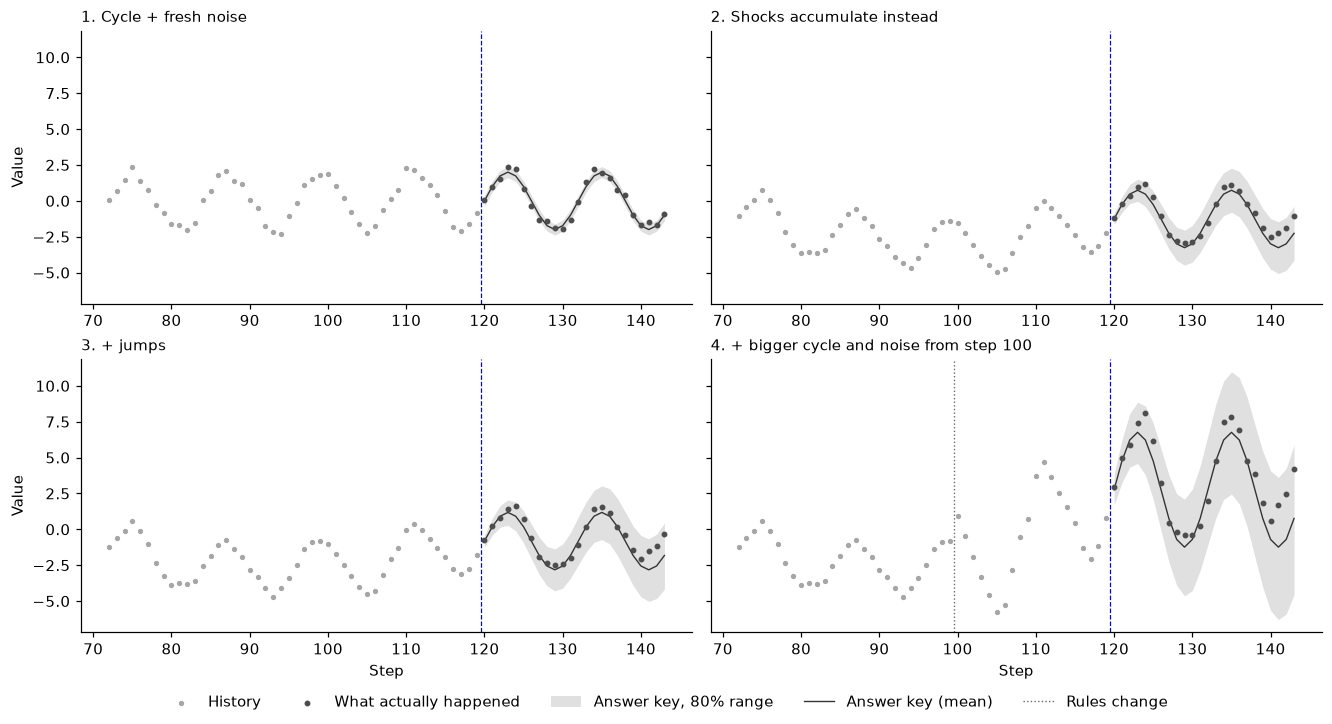

In [23]:
cycle = {'amplitude': 2., 'period': 12., 'sigma': .3}
walk = {**cycle, 'residual': 'random_walk'}
jumps = {**walk, 'jump_rate': .05, 'jump_sigma': 1.}
change = {**jumps, 'change_point': 100, 'changes': {'amplitude': 4., 'sigma': .8}}
ladder = [Scenario('composite', context_length=120, horizon=24, parameters=p, seed=11)
          for p in (cycle, walk, jumps, change)]
cases = [scenario.generate() for scenario in ladder]
paths = [np.r_[case.task.context.iloc[:, 0], case.observed.iloc[:, 0]] for case in cases]

wave = 2 * np.sin(2 * np.pi * np.arange(len(paths[0])) / 12)
np.testing.assert_allclose(np.diff(paths[1] - wave), (paths[0] - wave)[1:], atol=1e-12)  # the same shocks, now added up
gap_moves = np.flatnonzero(np.abs(np.diff(paths[2] - paths[1])) > 1e-9) + 1
assert len(gap_moves) < len(paths[2]) / 10    # adding jumps changes the path only where a jump lands
np.testing.assert_array_equal(paths[3][:100], paths[2][:100])  # the change leaves steps 0 to 99 alone

display(pd.DataFrame({
    'recipe': [scenario.display_name for scenario in ladder],
    'answer key spread, 1 step ahead': [np.sqrt(case.reference.variance[0, 0]) for case in cases],
    'answer key spread, 24 steps ahead': [np.sqrt(case.reference.variance[-1, 0]) for case in cases],
}).round(2))
print(f'Adding jumps changes the path at {len(gap_moves)} of {len(paths[2])} steps, where a jump landed: '
      f'{", ".join(map(str, gap_moves))}.')

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharey=True, layout='constrained')
titles = ['1. Cycle + fresh noise', '2. Shocks accumulate instead', '3. + jumps',
          '4. + bigger cycle and noise from step 100']
for ax, case, title in zip(axes.flat, cases, titles):
    draw_case(ax, case, title)
axes[1, 1].axvline(99.5, color='0.4', linestyle=':', linewidth=0.9, label='Rules change')
for ax in axes[1]:
    ax.set_xlabel('Step')
for ax in axes[:, 0]:
    ax.set_ylabel('Value')
fig.legend(*axes[1, 1].get_legend_handles_labels(), loc='outside lower center', ncol=6)
plt.show()

The spread is the answer key's standard deviation: how far off even a perfect forecaster should expect to be. With fresh noise it stays at 0.30 from 1 to 24 steps ahead, because each step's noise is new and the cycle is known. Once shocks accumulate it grows with the horizon, to 1.47 at 24 steps; jumps take it to 1.83, and the noisier rules from step 100 to 4.07. The mean changes too: with accumulated shocks it starts from where the history ended, because a shock that never fades is part of every future value.

The checks in the cell confirm the shared luck: the accumulated series is the fresh noise added up, jumps change the path only at the 9 steps where one landed, and the last two series match up to step 99.

## Financial recipes: one simulation, three units

The three financial recipes simulate log returns: the change in log price from one step to the next. `output` chooses how the series is reported: as those returns (`log_return`), as the log price, their running total starting from the log of `initial_price` (`log_price`), or as the price itself, the exponential of the log price (`price`). The answer key is converted the same way, and that conversion is where the care goes: the expected price is not the exponential of the expected log price.

In [24]:
#| export _process_common
def _to_values(returns, p):
    if p['output'] == 'log_return':
        return returns
    start = np.broadcast_to(np.log(p['initial_price']), returns.shape[1:])
    logs = np.concatenate([start[None], start + returns.cumsum(axis=0)], axis=0)
    return _exp(logs, 'Generated prices') if p['output'] == 'price' else logs


In [25]:
#| export _process_common
def _observed_returns(values, p, length):
    history = np.asarray(values[:length])
    if p['output'] == 'log_return':
        return history
    return np.diff(np.log(history) if p['output'] == 'price' else history, axis=0)

In [26]:
#| export _process_common
def _transform_samples(returns, p, last):
    if p['output'] == 'log_return':
        return returns
    logs = (np.log(last) if p['output'] == 'price' else last) + returns.cumsum(axis=1)
    return _exp(logs, 'Reference price draws') if p['output'] == 'price' else logs


## Merton jumps: a price that drifts, wiggles and sometimes jumps

On most steps the price moves by a small random percentage. Now and then, on average `jump_rate` times a year, it jumps by a larger one, typically about −10% with the defaults. `dt` is the length of one step in years: 1/252 for trading days (the default), 1/12 for months.

`mu` is the price's own expected growth rate: whatever the jumps, the answer key expects the price $h$ steps ahead to be $S_t e^{\mu h \Delta t}$. It describes how prices grow on average in the world being simulated, not a risk-neutral rate for pricing options. The expected log price grows more slowly. With `jump_rate=0` the recipe is geometric Brownian motion.

In symbols, one step's log return is $R=(\mu-\sigma^2/2-\lambda\kappa)\Delta t+\sigma\sqrt{\Delta t}Z+\sum_{i=1}^N J_i$, with $N\sim\mathrm{Poisson}(\lambda\Delta t)$ jumps, normal log jumps $J_i$ with mean $m_J$ and spread $s_J$, and $\kappa=\exp(m_J+s_J^2/2)-1$.

In [27]:
#| export processes
def _merton(p, length, horizon, n_targets, seed):
    rng = _streams(seed)
    count = length+horizon-(p['output'] != 'log_return')
    args = [p[key] for key in ('mu', 'sigma', 'jump_rate', 'jump_mean', 'jump_sigma', 'dt')]
    returns = np.array([_merton_increment(rng, None, *args) for _ in range(count)])
    values = _to_values(returns, p)
    last = float(values[length-1])
    mu, sigma, rate, jm, js, dt = args
    a = (mu-.5*sigma**2-rate*np.expm1(jm+.5*js**2)+rate*jm)*dt
    v = (sigma**2+rate*(js**2+jm**2))*dt
    steps = np.arange(1, horizon+1)
    if p['output'] == 'log_return':
        mean, covariance = np.full(horizon, a), np.eye(horizon)*v
    elif p['output'] == 'log_price':
        mean, covariance = last+steps*a, np.minimum.outer(steps, steps)*v
    else:
        k1, k2 = [_log_cumulant(k, *args) for k in (1., 2.)]
        mean = _exp(np.log(last)+steps*k1, 'Conditional price mean')
        with np.errstate(over='ignore', invalid='ignore'):
            covariance = np.outer(mean, mean)*np.expm1(np.minimum.outer(steps, steps)*(k2-2*k1))
    def sampler(n, sample_seed):
        rng = _streams(sample_seed, role=1)
        draws = np.column_stack([_merton_increment(rng, n, *args) for _ in range(horizon)])
        return _transform_samples(draws[..., None], p, last)
    conditioning = dict(output_units=p['output'], drift_convention='physical_expected_proportional_price_growth',
                        initialization='initial_price_at_index_zero' if p['output'] != 'log_return' else 'first_return_at_index_zero')
    gaussian = p['jump_rate'] == 0 and p['output'] != 'price'
    return values, mean, covariance, conditioning, None if gaussian else sampler, {}

### The same price in three units

One recipe with monthly steps (`dt=1/12`), generated three times from one seed: as prices, as log prices and as monthly returns. The histories are the same numbers in three units; the answer keys are not simple conversions of each other.

Last price 163.4. Over 24 months the answer key expects the price to grow +17.4%; the exponential of the expected log price says +7.0%.
The median price 24 months ahead is 176.8 in both units.


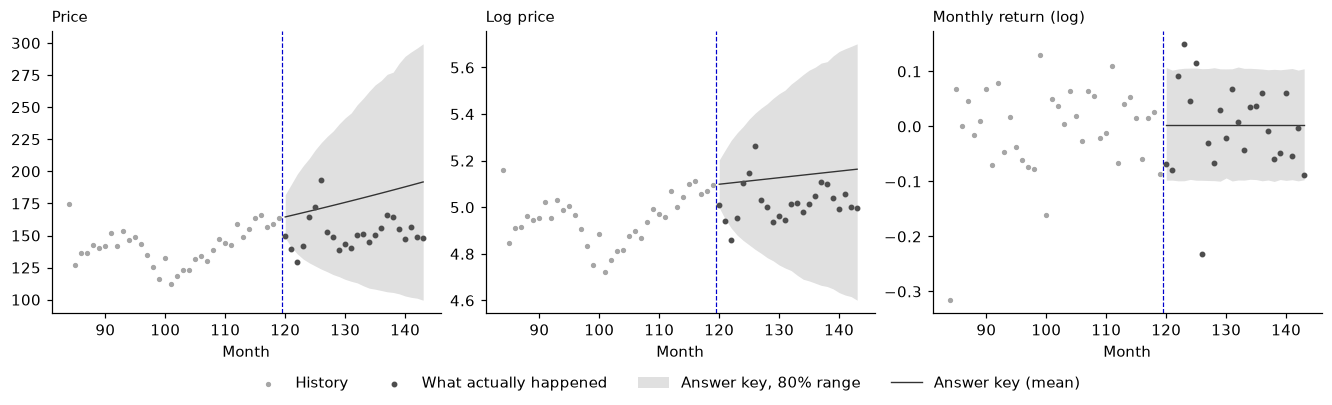

In [28]:
monthly = {'mu': .08, 'sigma': .25, 'jump_rate': 1., 'jump_mean': -.10, 'jump_sigma': .15, 'dt': 1 / 12}
units = {'price': 'Price', 'log_price': 'Log price', 'log_return': 'Monthly return (log)'}
merton = {unit: Scenario('merton_jump_diffusion', context_length=120, horizon=24,
                         parameters={**monthly, 'output': unit}).generate(seed=14)
          for unit in units}
price, log_price = merton['price'], merton['log_price']
np.testing.assert_allclose(np.log(price.task.context), log_price.task.context)  # one history, two units

last = price.task.context.iloc[-1, 0]
expected = price.reference.mean[-1, 0] / last - 1
converted = np.exp(log_price.reference.mean[-1, 0]) / last - 1
median_price = price.reference.quantile((.5,))[-1, 0, 0]
assert np.isclose(expected, np.exp(monthly['mu'] * 24 * monthly['dt']) - 1)  # mu is the price's expected growth rate
assert converted < expected                                                   # exp(expected log price) is too low
np.testing.assert_allclose(median_price, np.exp(log_price.reference.quantile((.5,))[-1, 0, 0]))  # medians convert

print(f'Last price {last:.1f}. Over 24 months the answer key expects the price to grow {expected:+.1%}; '
      f'the exponential of the expected log price says {converted:+.1%}.')
print(f'The median price 24 months ahead is {median_price:.1f} in both units.')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout='constrained')
for ax, (unit, title) in zip(axes, units.items()):
    draw_case(ax, merton[unit], title, last=36)
    ax.set_xlabel('Month')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=4)
plt.show()

One path, three different answer keys. For returns the answer key is flat and equally wide at every step, because each month's return is new. For log prices its mean is a straight line and its range widens with the horizon. For prices the range stretches much further above the last price than below it, because percentage moves compound.

Means don't convert: the answer key expects the price to grow 17.4% over 24 months, exactly $e^{0.08\times 2}-1$, but the exponential of the expected log price says 7.0%. A model that forecasts log prices and converts its mean with `exp` is too low by the difference and still passes every output check; [Composed and financial stresses](26_composed_and_financial_stresses.ipynb) hunts this bug. Medians do convert: 176.8 in both units.

## GARCH: calm and stormy periods

A big move today makes a big move tomorrow more likely, so big moves come in clusters, even though the direction of each move stays unpredictable. Tomorrow's variance is $h_{t+1}=\omega+\alpha(R_t-\mu)^2+\beta h_t$: a constant, plus a share of today's squared surprise, plus most of today's variance. `alpha + beta` must stay below 1, or the variance would grow forever.

The answer key rebuilds today's variance from the observed returns, then projects its expected value forward exactly, back toward the long-run level $\omega/(1-\alpha-\beta)$. Its possible futures are simulated, each updating its variance from its own shocks, so beyond the first step they have fatter tails than a bell curve and the quantiles come from simulation.

GARCH reports returns or log prices, not prices: the expected future price of a GARCH series can be infinite, and a bell-curve shortcut would hide that.

In [29]:
#| export processes
def _garch(p, length, horizon, n_targets, seed):
    rng = _rng(seed)
    count = length+horizon-(p['output'] != 'log_return')
    returns = np.empty(count)
    variance = p['initial_variance']
    for t in range(count):
        shock = np.sqrt(variance)*rng.standard_normal()
        returns[t] = p['mu']+shock
        variance = p['omega']+p['alpha']*shock**2+p['beta']*variance
    values = _to_values(returns, p)
    # Reconstruct the next variance from observed data only, including for log levels.
    next_variance = p['initial_variance']
    for value in _observed_returns(values, p, length):
        next_variance = p['omega']+p['alpha']*(value-p['mu'])**2+p['beta']*next_variance
    variances = np.empty(horizon)
    variances[0] = next_variance
    for h in range(1, horizon):
        variances[h] = p['omega']+(p['alpha']+p['beta'])*variances[h-1]
    last = float(values[length-1])
    if p['output'] == 'log_return':
        mean, covariance = np.full(horizon, p['mu']), np.diag(variances)
    else:
        mean = last+np.arange(1, horizon+1)*p['mu']
        covariance = np.cumsum(variances)[np.minimum.outer(np.arange(horizon), np.arange(horizon))]
    def sampler(n, sample_seed):
        rng = _rng(sample_seed, role=1)
        variance = np.full(n, next_variance)
        draws = np.empty((n, horizon))
        for h in range(horizon):
            shock = np.sqrt(variance)*rng.standard_normal(n)
            draws[:, h] = p['mu']+shock
            variance = p['omega']+p['alpha']*shock**2+p['beta']*variance
        return _transform_samples(draws[..., None], p, last)
    conditioning = dict(output_units=p['output'], next_variance_from_observed_history=float(next_variance),
                        initialization='specified_initial_variance')
    return values, mean, covariance, conditioning, sampler, {}

### After a calm, after a storm

The default recipe (`omega=1e-5`, `alpha=0.08`, `beta=0.9`) has a long-run spread of about 2.2% per step. We generate 60 histories of 250 steps, keep the one that ends calmest and the one that ends stormiest, and ask each answer key about the next 60 steps.

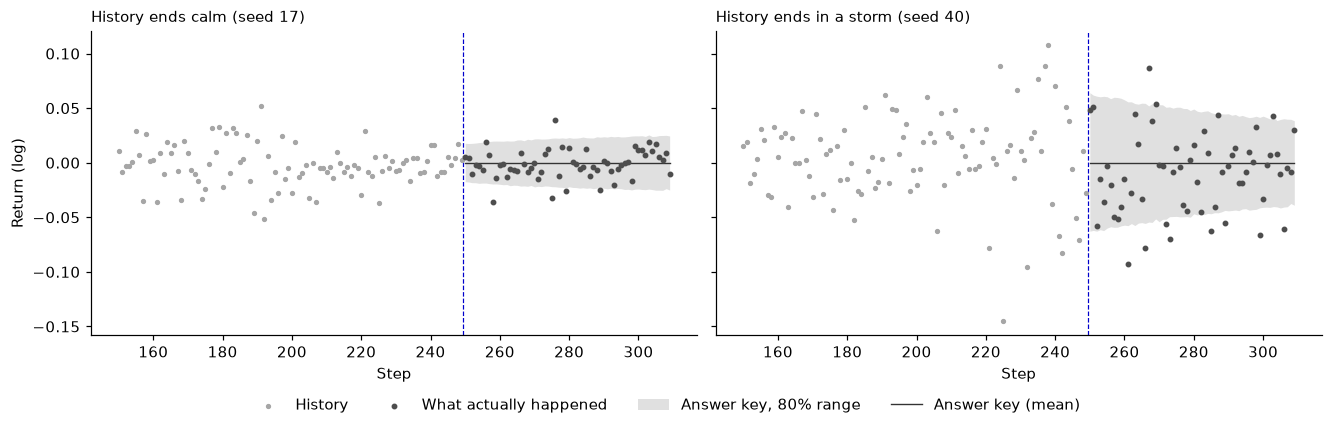

After the calm: spread 1.4% one step ahead, 2.0% sixty steps ahead; kurtosis sixty steps ahead 3.9.
After the storm: spread 4.9% one step ahead, 3.3% sixty steps ahead; kurtosis sixty steps ahead 5.7.
Long-run spread 2.2%; a bell curve has kurtosis 3.
Over 5,000 steps, the correlation between one return and the next is -0.02; between one squared return and the next it is 0.14.


In [30]:
garch = Scenario('garch', context_length=250, horizon=60)
ending = {seed: garch.generate(seed).reference.conditioning['next_variance_from_observed_history']
          for seed in range(60)}
calm_seed, storm_seed = min(ending, key=ending.get), max(ending, key=ending.get)
calm, storm = garch.generate(calm_seed), garch.generate(storm_seed)
long_run = np.sqrt(1e-5 / (1 - .08 - .9))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, layout='constrained')
for ax, case, title in zip(axes, (calm, storm), (f'History ends calm (seed {calm_seed})',
                                                 f'History ends in a storm (seed {storm_seed})')):
    draw_case(ax, case, title, last=100)
    ax.set_xlabel('Step')
axes[0].set_ylabel('Return (log)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=4)
plt.show()

spread = {name: np.sqrt(case.reference.variance[[0, -1], 0]) for name, case in (('calm', calm), ('storm', storm))}
tails = {name: kurtosis(case.reference.sample(20000, seed=1)[:, -1, 0], fisher=False)
         for name, case in (('calm', calm), ('storm', storm))}
assert spread['calm'][0] < long_run < spread['storm'][0]                 # the history sets the next step's spread
assert spread['calm'][1] > spread['calm'][0] and spread['storm'][1] < spread['storm'][0]  # both head back
assert min(tails.values()) > 3                                           # fatter tails than a bell curve
for name in spread:
    print(f'After the {name}: spread {spread[name][0]:.1%} one step ahead, {spread[name][1]:.1%} sixty steps ahead; '
          f'kurtosis sixty steps ahead {tails[name]:.1f}.')
print(f'Long-run spread {long_run:.1%}; a bell curve has kurtosis 3.')

returns = Scenario('garch', context_length=5000, horizon=1).generate(seed=0).task.context.iloc[:, 0]
print(f'Over 5,000 steps, the correlation between one return and the next is {returns.autocorr():.2f}; '
      f'between one squared return and the next it is {(returns ** 2).autocorr():.2f}.')

After the calm the range starts narrow (1.4% one step ahead) and widens toward the long-run 2.2%; after the storm it starts wide (4.9%) and narrows. With `alpha + beta = 0.98` volatility settles slowly, so neither gets there in 60 steps (2.0% and 3.3%). A forecast with one fixed range would be overconfident after the storm and overcautious after the calm.

Sixty steps ahead the tails are fatter than a bell curve's (kurtosis 3.9 and 5.7, against 3). The last line shows the clustering itself: one return says almost nothing about the direction of the next (correlation −0.02), but its size says something about the next one's size (0.14).

## Hidden regimes: a market that switches between states you can't see

A hidden switch picks a regime before every return. By default there are two: calm (growth 8% a year, volatility 15%) and stormy (−15% a year, volatility 45%); a calm step stays calm with probability 0.97, a stormy one stormy with 0.92. Each regime can have its own jumps.

The model sees the returns, never the regime, and neither does the answer key: a forward filter updates each regime's probability with every observed return, and the forecast averages over those probabilities and every possible future switch. It is the best forecast for someone who knows the recipe but not the hidden state.

With jumps, one return could hide any number of jumps; the filter counts them up to a cut-off, so that answer key is labeled approximate (see **Limits**). Regimes with zero volatility can't be mixed with random ones; the error message says why.

In [31]:
#| export _process_common
def _regime_arrays(p):
    return [np.asarray(p[key], dtype=float) for key in ('regime_mu', 'regime_sigma', 'regime_jump_rate', 'regime_jump_mean', 'regime_jump_sigma')]

In [32]:
#| export _process_common
def _common_deterministic_return(p):
    mu, sigma, rate, jm, js = _regime_arrays(p)
    return bool(np.all(sigma == 0) and np.all((rate == 0) | ((jm == 0) & (js == 0)))
                and np.all(mu == mu[0]))

In [33]:
#| export processes
def _emission_components(p):
    mu, sigma, rate, jm, js = _regime_arrays(p)
    dt = p['dt']
    components = []
    tails = []
    for m, s, r, j, z in zip(mu, sigma, rate, jm, js):
        intensity = r*dt
        limit = 0 if intensity == 0 else int(poisson.ppf(1-_TAIL_TOLERANCE, intensity))
        counts = np.arange(limit+1)
        logweights = poisson.logpmf(counts, intensity)
        centers = (m-.5*s*s-r*np.expm1(j+.5*z*z))*dt+counts*j
        variances = s*s*dt+counts*z*z
        components.append((logweights, centers, variances))
        tails.append(float(poisson.sf(limit, intensity)))
    return components, max(tails)

In [34]:
#| export processes
def _emission_loglikelihood(value, components, prior):
    # At an atom, probability mass dominates continuous density. This handles
    # deterministic regimes and deterministic jumps without arbitrary jitter.
    atom_terms = []
    density_terms = []
    for logweights, centers, variances in components:
        atom = (variances == 0) & (centers == value)
        atom_terms.append(logsumexp(logweights[atom]) if np.any(atom) else -np.inf)
        continuous = variances > 0
        if np.any(continuous):
            v = variances[continuous]
            density_terms.append(logsumexp(logweights[continuous]-.5*(np.log(2*np.pi*v)+(value-centers[continuous])**2/v)))
        else:
            density_terms.append(-np.inf)
    return np.asarray(atom_terms if np.any(np.isfinite(atom_terms) & (prior > 0)) else density_terms)

In [35]:
#| export processes
def _filter_regimes(returns, p):
    transition = np.asarray(p['transition'])
    posterior = np.asarray(p['initial_probs'])
    if _common_deterministic_return(p):
        # These regimes have identical deterministic emissions. Reconstructing
        # log returns from levels can introduce roundoff, but conveys no state
        # information. Propagating the prior is therefore exact.
        return posterior@np.linalg.matrix_power(transition, len(returns)), 0.
    components, tail = _emission_components(p)
    for value in returns:
        prior = posterior@transition
        with np.errstate(divide='ignore'):
            logweights = np.log(prior)+_emission_loglikelihood(value, components, prior)
        normalization = logsumexp(logweights)
        if not np.isfinite(normalization):
            raise ValueError('Observed return has zero numerical likelihood under the regime filter; rescale parameters or avoid degenerate indistinguishable emissions')
        posterior = np.exp(logweights-normalization)
    return posterior, tail

In [36]:
#| export processes
def _markov_price_moments(posterior, transition, mu, sigma, rate, jm, js, dt, last, horizon):
    """Stable law-of-total-covariance calculation, without raw-moment subtraction.

    Track price mean/variance conditional on each state. State-mixture
    variances use centered differences; multiplier variances use expm1.
    This preserves exact zero uncertainty for indistinguishable deterministic
    regimes and avoids cancellation of nearly equal large price moments.
    """
    growth = _exp(mu*dt, 'Regime expected price multiplier')
    with np.errstate(over='ignore', invalid='ignore'):
        squared_jump = np.exp(2*jm+js*js)*np.expm1(js*js) + np.expm1(jm+.5*js*js)**2
        spread = (sigma*sigma + rate*squared_jump)*dt
        growth_variance = growth*growth*np.expm1(spread)
        growth_second = growth*growth + growth_variance
    _finite(growth_second, 'Regime second price multiplier moment')
    probs = np.asarray(posterior, dtype=float)
    conditional_mean = np.full(len(probs), last)
    conditional_variance = np.zeros(len(probs))
    states = []
    mean = np.empty(horizon)
    for h in range(horizon):
        joint = probs[:, None]*transition
        next_probs = joint.sum(axis=0)
        supported = next_probs > 0
        weights = np.divide(joint, next_probs[None, :], out=np.zeros_like(joint), where=supported[None, :])
        # An anchor preserves identical conditional means exactly.
        anchor = conditional_mean[0]
        incoming_mean = anchor+(weights*(conditional_mean-anchor)[:, None]).sum(axis=0)
        incoming_variance = (weights*(conditional_variance[:, None]
                                      +(conditional_mean[:, None]-incoming_mean[None, :])**2)).sum(axis=0)
        conditional_variance = incoming_variance*growth_second + incoming_mean**2*growth_variance
        conditional_mean = incoming_mean*growth
        probs = next_probs/next_probs.sum()
        mean[h] = conditional_mean[0]+probs@(conditional_mean-conditional_mean[0])
        states.append((probs.copy(), conditional_mean.copy(), conditional_variance.copy()))
    covariance = np.empty((horizon, horizon))
    growth_transition = transition*growth
    for h, (probs, state_mean, state_variance) in enumerate(states):
        expected_growth = np.ones(len(probs))
        centered_mean = state_mean-mean[h]
        for j in range(h, horizon):
            if j > h:
                expected_growth = growth_transition@expected_growth
            covariance[h, j] = covariance[j, h] = probs@(expected_growth*state_variance
                + centered_mean*(state_mean*expected_growth-mean[j]))
    return mean, covariance

In [37]:
#| export processes
def _markov(p, length, horizon, n_targets, seed):
    rng = _streams(seed)
    transition = np.asarray(p['transition'])
    arrays = _regime_arrays(p)
    count = length+horizon-(p['output'] != 'log_return')
    state = rng['states'].choice(len(transition), p=p['initial_probs'])
    returns = np.empty(count)
    for t in range(count):
        state = rng['states'].choice(len(transition), p=transition[state])
        returns[t] = _merton_increment(rng, None, *[a[state] for a in arrays], p['dt'])
    values = _to_values(returns, p)
    posterior, tail = _filter_regimes(_observed_returns(values, p, length), p)
    mu, sigma, rate, jm, js = arrays
    dt = p['dt']
    a = (mu-.5*sigma*sigma-rate*np.expm1(jm+.5*js*js)+rate*jm)*dt
    v = (sigma*sigma+rate*(js*js+jm*jm))*dt
    last = float(values[length-1])
    powers = [np.linalg.matrix_power(transition, h) for h in range(horizon+1)]
    if p['output'] == 'price':
        mean, covariance = _markov_price_moments(posterior, transition, *arrays, dt, last, horizon)
    else:
        probabilities = [posterior@powers[h] for h in range(1, horizon+1)]
        probabilities = [probs/probs.sum() for probs in probabilities]
        mean = np.array([a[0]+probs@(a-a[0]) for probs in probabilities])
        covariance = np.empty((horizon, horizon))
        for h, probs in enumerate(probabilities):
            centered = a-mean[h]
            covariance[h, h] = probs@(v+centered*centered)
            for j in range(h+1, horizon):
                future_mean = a[0]+powers[j-h]@(a-a[0])
                covariance[h, j] = covariance[j, h] = probs@(centered*(future_mean-mean[j]))
        if p['output'] == 'log_price':
            mean = last+np.cumsum(mean)
            covariance = covariance.cumsum(axis=0).cumsum(axis=1)
    def sampler(n, sample_seed):
        rng = _streams(sample_seed, role=1)
        states = rng['states'].choice(len(transition), size=n, p=posterior)
        draws = np.empty((n, horizon))
        for h in range(horizon):
            uniforms = rng['states'].random(n)
            cumulative = transition[states].cumsum(axis=1)
            cumulative[:, -1] = 1.
            states = (uniforms[:, None] > cumulative).sum(axis=1)
            draws[:, h] = _merton_increment(rng, n, *[a[states] for a in arrays], dt)
        return _transform_samples(draws[..., None], p, last)
    has_jumps = bool(np.any(rate > 0))
    conditioning = dict(output_units=p['output'], state_posterior=posterior.tolist(),
                        state_inference='forward_filter_observed_returns_only',
                        hidden_states_exposed_to_model=False,
                        emission_poisson_tail_bound=tail,
                        filter_note='truncated_emission_mixture; tail_bound_is_not_a_posterior_error_bound' if has_jumps else 'Gaussian_emissions',
                        moments_conditioning='numerically_filtered_posterior' if has_jumps else 'filtered_posterior')
    return values, mean, covariance, conditioning, sampler, dict(sampler_kind='approximate_conditional') if has_jumps else {}

### The answer key works out the regime; it never peeks

Below, the default recipe over 200 daily returns. The answer key's probability of a storm is recomputed every four steps from the returns seen so far. The shading shows the true regime, rebuilt here from the seed's own regime stream for this plot only: neither the model nor the answer key ever sees it.

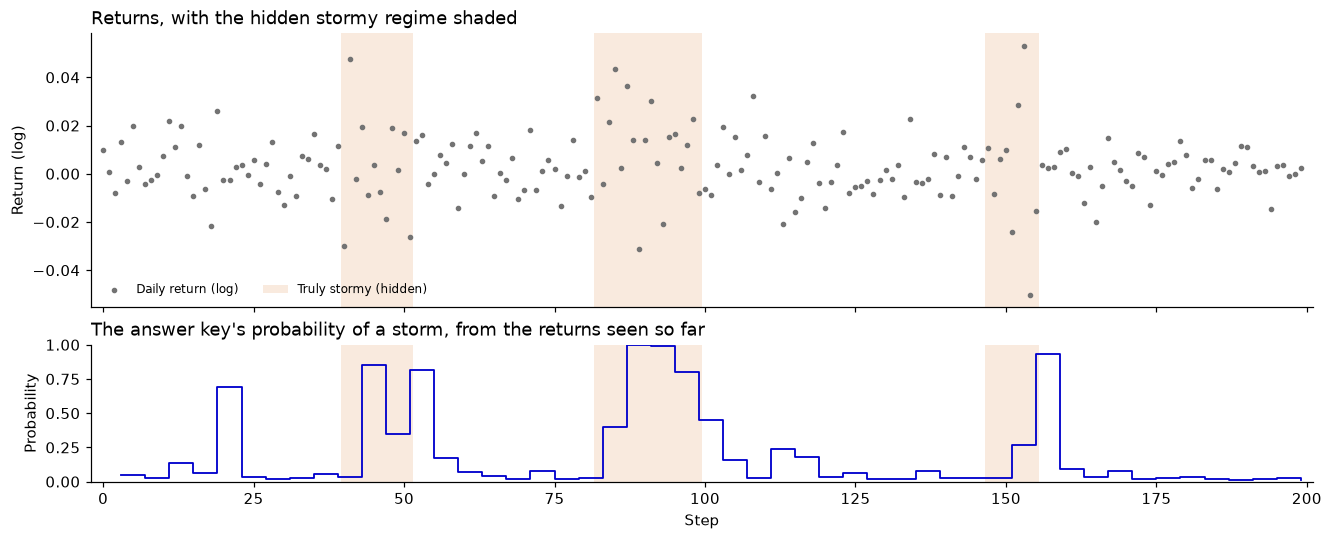

Mean probability of a storm: 0.63 when the market is truly stormy, 0.07 when it is calm.


In [38]:
seed, steps = 21, 200
case = Scenario('markov_switching', context_length=steps, horizon=1).generate(seed)
recipe, returns = case.manifest['parameters'], case.task.context.iloc[:, 0]

# The true regimes, replayed from this seed's regime stream (the plot's shading only).
regime_stream = _streams(seed)['states']
state = regime_stream.choice(2, p=recipe['initial_probs'])
stormy = []
for _ in range(steps):
    state = regime_stream.choice(2, p=recipe['transition'][state])
    stormy.append(state == 1)
stormy = np.array(stormy)

# The answer key's probability of a storm, from the returns up to each checkpoint.
checkpoints = np.arange(4, steps + 1, 4)
belief = np.array([Scenario('markov_switching', context_length=t, horizon=1).generate(seed)
                   .reference.conditioning['state_posterior'][1] for t in checkpoints])
truly_stormy = stormy[checkpoints - 1]
assert belief[truly_stormy].mean() > .5 > belief[~truly_stormy].mean()  # it follows the storms without seeing them

fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 4.8), sharex=True, height_ratios=[2, 1],
                                  layout='constrained')
edges = np.flatnonzero(np.diff(np.r_[0, stormy.astype(int), 0]))
for ax in (top, bottom):
    for start, stop in zip(edges[::2], edges[1::2]):
        ax.axvspan(start - .5, stop - .5, color='#D55E00', alpha=.13, linewidth=0)
top.scatter(returns.index, returns, s=7, color='0.45', label='Daily return (log)')
top.axvspan(-10, -9, color='#D55E00', alpha=.13, linewidth=0, label='Truly stormy (hidden)')
top.set(xlim=(-2, steps + 1), ylabel='Return (log)', title='Returns, with the hidden stormy regime shaded')
top.legend(loc='lower left', ncol=2, fontsize=8)
bottom.step(checkpoints - 1, belief, where='post', color=BLUE, linewidth=1.2)
bottom.set(ylim=(0, 1), xlabel='Step', ylabel='Probability',
           title="The answer key's probability of a storm, from the returns seen so far")
plt.show()
print(f'Mean probability of a storm: {belief[truly_stormy].mean():.2f} when the market is truly stormy, '
      f'{belief[~truly_stormy].mean():.2f} when it is calm.')

The probability of a storm rises with each storm and falls back after it, without ever seeing the regime: on average it is 0.63 while the market is truly stormy and 0.07 while it is calm. It is not an oracle. It follows each switch a few steps late, in and out, because it has to wait for evidence, and it raises a false alarm near step 20 after two large moves in calm weather. That is exactly what the answer key should be: the best anyone can do from the history.

## One entry point for every family

`generate_process` checks the settings with `resolve_process`, then calls the one-series builder above or, for several series, the joint builder in chapter 15. `Scenario` calls the same builders with the settings it resolved once, when it was created, so changing a `Scenario`'s settings means creating a new one.

In [39]:
#| export processes
def _generate_resolved_process(kind, parameters, context_length, horizon, n_targets=1, seed=0):
    entry = _PROCESS_REGISTRY[kind]
    builder = globals()[entry['scalar']] if n_targets == 1 else getattr(joint_processes, entry['joint'])
    return _build_case(builder, kind, parameters, context_length, horizon, n_targets, seed)


def generate_process(kind, parameters, context_length, horizon, n_targets=1, seed=0):
    """Resolve a controlled mechanism and generate a history-conditioned case.

    Hidden states, future shocks and schedules remain evaluator-only.
    Scenario uses the same builders with its already-resolved parameters.
    """
    resolved = resolve_process(kind, parameters, context_length, horizon, n_targets, seed)
    return _generate_resolved_process(kind, resolved, context_length, horizon, n_targets, seed)


## How exact is each answer key?

Every answer key records how it was made, in `case.reference.conditioning`. The table translates those labels for seven recipes: where the mean and spread come from, how possible futures are drawn, and where the quantiles come from.

In [40]:
recipes = [
    Scenario('composite', parameters={'amplitude': 2., 'sigma': .3}),
    Scenario('composite', parameters={**jumps}),
    Scenario('merton_jump_diffusion', parameters={'jump_rate': 0., 'output': 'log_price'}),
    Scenario('merton_jump_diffusion', parameters={'output': 'price'}),
    Scenario('garch'),
    Scenario('markov_switching'),
    Scenario('markov_switching', parameters={'regime_jump_rate': [3., 12.], 'regime_jump_mean': [0., -.06],
                                             'regime_jump_sigma': [.03, .10]}),
]


def how_it_was_made(reference):
    labels = reference.conditioning
    gaussian = reference.kind == 'analytic_conditional'  # a bell-curve law: formulas for everything
    given = {'filtered_posterior': ', given the filtered regime odds',
             'numerically_filtered_posterior': ', given numerically filtered regime odds'}
    draws = {'exact_conditional': 'simulated from the true recipe',
             'approximate_conditional': 'simulated from an approximation'}
    return {'mean and spread': 'exact formulas' + given.get(labels.get('moments_conditioning'), ''),
            'possible futures': 'exact (bell curve)' if gaussian else draws[labels['sampler_kind']],
            'quantiles': 'exact formulas' if gaussian
                         else f"estimated from {labels['quantile_samples']:,} simulated futures"}


exactness = pd.DataFrame([how_it_was_made(s.generate(seed=1).reference) for s in recipes],
                         index=pd.Index([s.display_name for s in recipes], name='recipe'))
assert list(exactness['possible futures']).count('simulated from an approximation') == 1  # regimes with jumps only
display(exactness)

,mean and spread,possible futures,quantiles
recipe,,,
Seasonality + white noise,exact formulas,exact (bell curve),exact formulas
Seasonality + accumulated shocks + jumps,exact formulas,simulated from the true recipe,"estimated from 8,192 simulated futures"
Geometric Brownian motion (log price),exact formulas,exact (bell curve),exact formulas
Merton jump diffusion (price),exact formulas,simulated from the true recipe,"estimated from 8,192 simulated futures"
"GARCH(1,1) (log returns)",exact formulas,simulated from the true recipe,"estimated from 8,192 simulated futures"
Hidden Markov regimes (log returns),"exact formulas, given the filtered regime odds",simulated from the true recipe,"estimated from 8,192 simulated futures"
Hidden regimes + jumps (log returns),"exact formulas, given numerically filtered regime odds",simulated from an approximation,"estimated from 8,192 simulated futures"


Bell-curve recipes (fresh noise, and geometric Brownian motion in log prices) get exact formulas for everything. The others keep exact means and spreads but simulate their possible futures from the true recipe and estimate quantiles from 8,192 of them. Only with jumps do the hidden regimes' odds become a numerical approximation, so only that recipe is labeled approximate; [Composed and financial stresses](26_composed_and_financial_stresses.ipynb) shows what that changes for statistical checks.

**Limits.** An answer key knows the true settings, an advantage no fitted model has, so read it as the best possible forecast, not a realistic target. Quantiles estimated from simulated futures carry a small simulation error. With regime-specific jumps the filter stops counting jumps per step once the probability it leaves out is below $10^{-12}$; that bounds the jump count, not the error in the regime probabilities, which is why those answer keys are labeled approximate. These are synthetic series: doing well on them promises nothing about real markets.

## Change one thing

- In the ladder, move `change_point` to 130, after the history ends. The history no longer shows the new rules, but the answer key still knows them.
- Set `jump_rate=0` in the monthly Merton recipe: its name becomes geometric Brownian motion, and in log-price units the answer key is an exact bell curve.
- Give GARCH `alpha=0.15` and `beta=0.8`: storms flare higher and fade faster.
- Make the hidden regimes harder to tell apart with `regime_sigma=[.15, .25]`: the probability of a storm rarely rises above one half.

**Next:** [Composed and financial stresses](26_composed_and_financial_stresses.ipynb) puts these recipes to work on real models. For several series that move together, read [Joint controlled processes](15_joint_processes.ipynb).